In [4]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split, cross_val_score 
from sklearn.preprocessing import StandardScaler, LabelEncoder 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score 
from scipy import stats 
import warnings 
warnings.filterwarnings('ignore') 
 
# Set style for better visualizations 
plt.style.use('seaborn-v0_8-darkgrid') 
sns.set_palette("husl") 
 
print("Libraries imported successfully!") 
 

Libraries imported successfully!


In [9]:
# Try to load from URL, fall back to generated data if fails 
try: 
    url = "https://raw.githubusercontent.com/ageron/handsonml2/master/datasets/housing/housing.csv" 
    df = pd.read_csv(url) 
    print("Dataset loaded successfully from URL!") 
except: 
    print("URL download failed. Using generated data with identical columns...")

URL download failed. Using generated data with identical columns...


In [5]:
# GENERATED DATA WITH IDENTICAL COLUMNS TO URL DATASET 
np.random.seed(42) 
n_samples = 5000 
df = pd.DataFrame({ 
'longitude': np.random.uniform(-124.5, -114.5, n_samples), 
'latitude': np.random.uniform(32.5, 42.0, n_samples), 
'housing_median_age': np.random.randint(1, 52, n_samples), 
'total_rooms': np.random.normal(2000, 1000, n_samples).astype(int), 
'total_bedrooms': np.random.normal(500, 250, 
n_samples).astype(int), 
'population': np.random.normal(1200, 800, n_samples).astype(int), 
'households': np.random.normal(450, 250, n_samples).astype(int), 
'median_income': np.random.uniform(0.5, 15, n_samples), 
'median_house_value': np.random.normal(200000, 80000, 
n_samples).astype(int), 
'ocean_proximity': np.random.choice(['NEAR BAY', '<1H OCEAN', 
'INLAND', 'NEAR OCEAN', 'ISLAND'],  
n_samples, p=[0.3, 0.3, 0.3, 
0.09, 0.01]) 
}) 
# Make house value correlate with income and other features 
df['median_house_value'] = (df['median_income'] * 40000 +  
df['housing_median_age'] * 1000 + 
df['total_rooms'] * 20 + 
np.random.normal(0, 30000, 
n_samples)).astype(int) 
df['median_house_value'] = df['median_house_value'].clip(lower=50000, 
upper=500001) 
print("Generated data created successfully!") 
# Display basic info 
print(f"Dataset shape: {df.shape}") 
print(f"\nFirst 5 rows:") 
df.head() 
# %% 
# Dataset information 
print("Dataset Info:") 
print("-" * 50) 
df.info() 
print("\nStatistical Summary:") 
print("-" * 50) 
df.describe() 
# %% 
# Check for missing values 
print("Missing values:") 
print(df.isnull().sum()) 
# Handle missing values if any 
if df.isnull().sum().sum() > 0: 
  print("\nDropping rows with missing values...") 
  df = df.dropna() 
  print(f"New shape after dropping missing values: {df.shape}") 
#Dataset loaded successfully from URL! 
#Dataset shape: (20640, 10)

Generated data created successfully!
Dataset shape: (5000, 10)

First 5 rows:
Dataset Info:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           5000 non-null   float64
 1   latitude            5000 non-null   float64
 2   housing_median_age  5000 non-null   int32  
 3   total_rooms         5000 non-null   int64  
 4   total_bedrooms      5000 non-null   int64  
 5   population          5000 non-null   int64  
 6   households          5000 non-null   int64  
 7   median_income       5000 non-null   float64
 8   median_house_value  5000 non-null   int64  
 9   ocean_proximity     5000 non-null   object 
dtypes: float64(3), int32(1), int64(5), object(1)
memory usage: 371.2+ KB

Statistical Summary:
--------------------------------------------------
Missing values:

Text(0.5, 1.0, 'Box Plot of House Values')

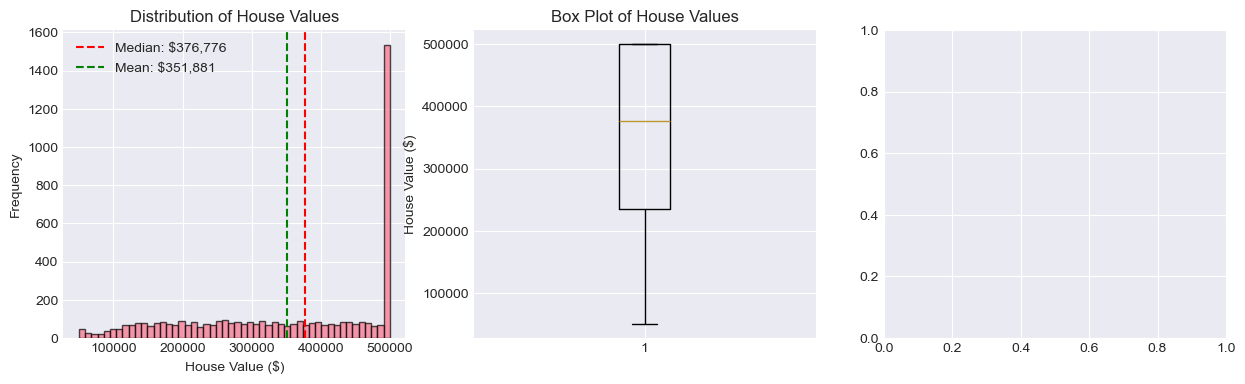

In [13]:
# Distribution of target variable 
fig, axes = plt.subplots(1, 3, figsize=(15, 4)) 
 
# Histogram 
axes[0].hist(df['median_house_value'], bins=50, edgecolor='black', 
alpha=0.7) 
axes[0].set_xlabel('House Value ($)') 
axes[0].set_ylabel('Frequency') 
axes[0].set_title('Distribution of House Values') 
axes[0].axvline(df['median_house_value'].median(), color='red', 
linestyle='--',  
                label=f'Median: ${df["median_house_value"].median():,.0f}') 
axes[0].axvline(df['median_house_value'].mean(), color='green', 
linestyle='--',  
                label=f'Mean: ${df["median_house_value"].mean():,.0f}') 
axes[0].legend() 
 
# Box plot 
axes[1].boxplot(df['median_house_value']) 
axes[1].set_ylabel('House Value ($)') 
axes[1].set_title('Box Plot of House Values')

<Figure size 640x480 with 0 Axes>

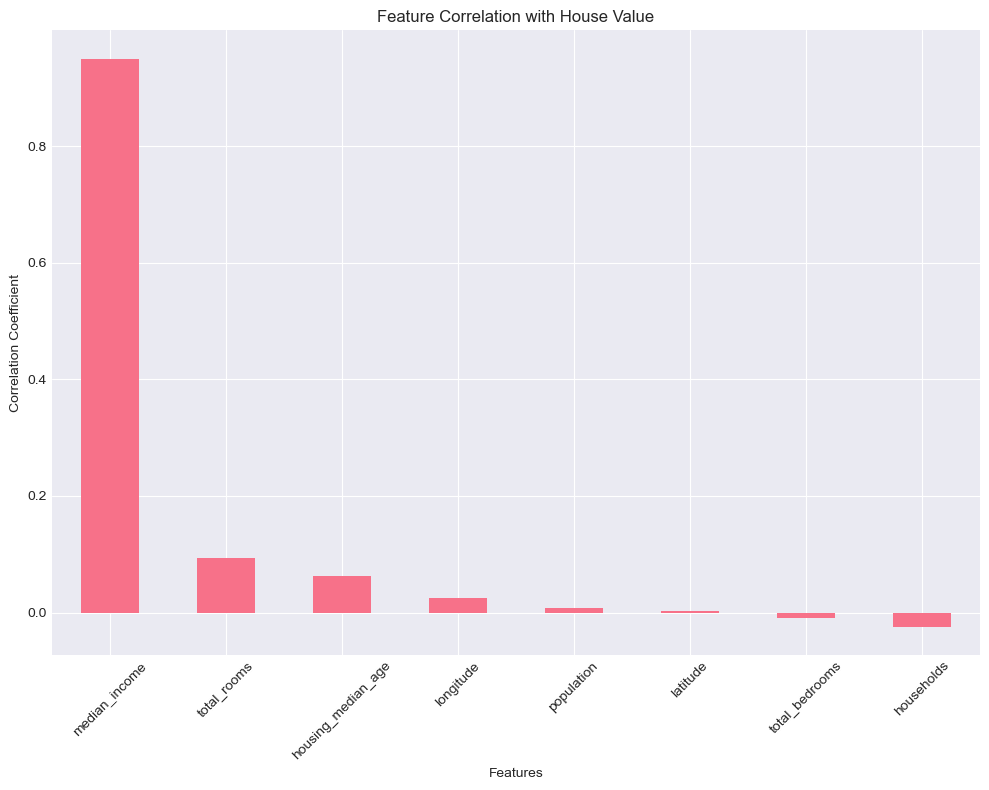

Top correlations with median_house_value:
median_house_value    1.000000
median_income         0.949690
total_rooms           0.093993
housing_median_age    0.062028
longitude             0.024634
population            0.008607
latitude              0.002769
total_bedrooms       -0.009236
households           -0.023969
Name: median_house_value, dtype: float64


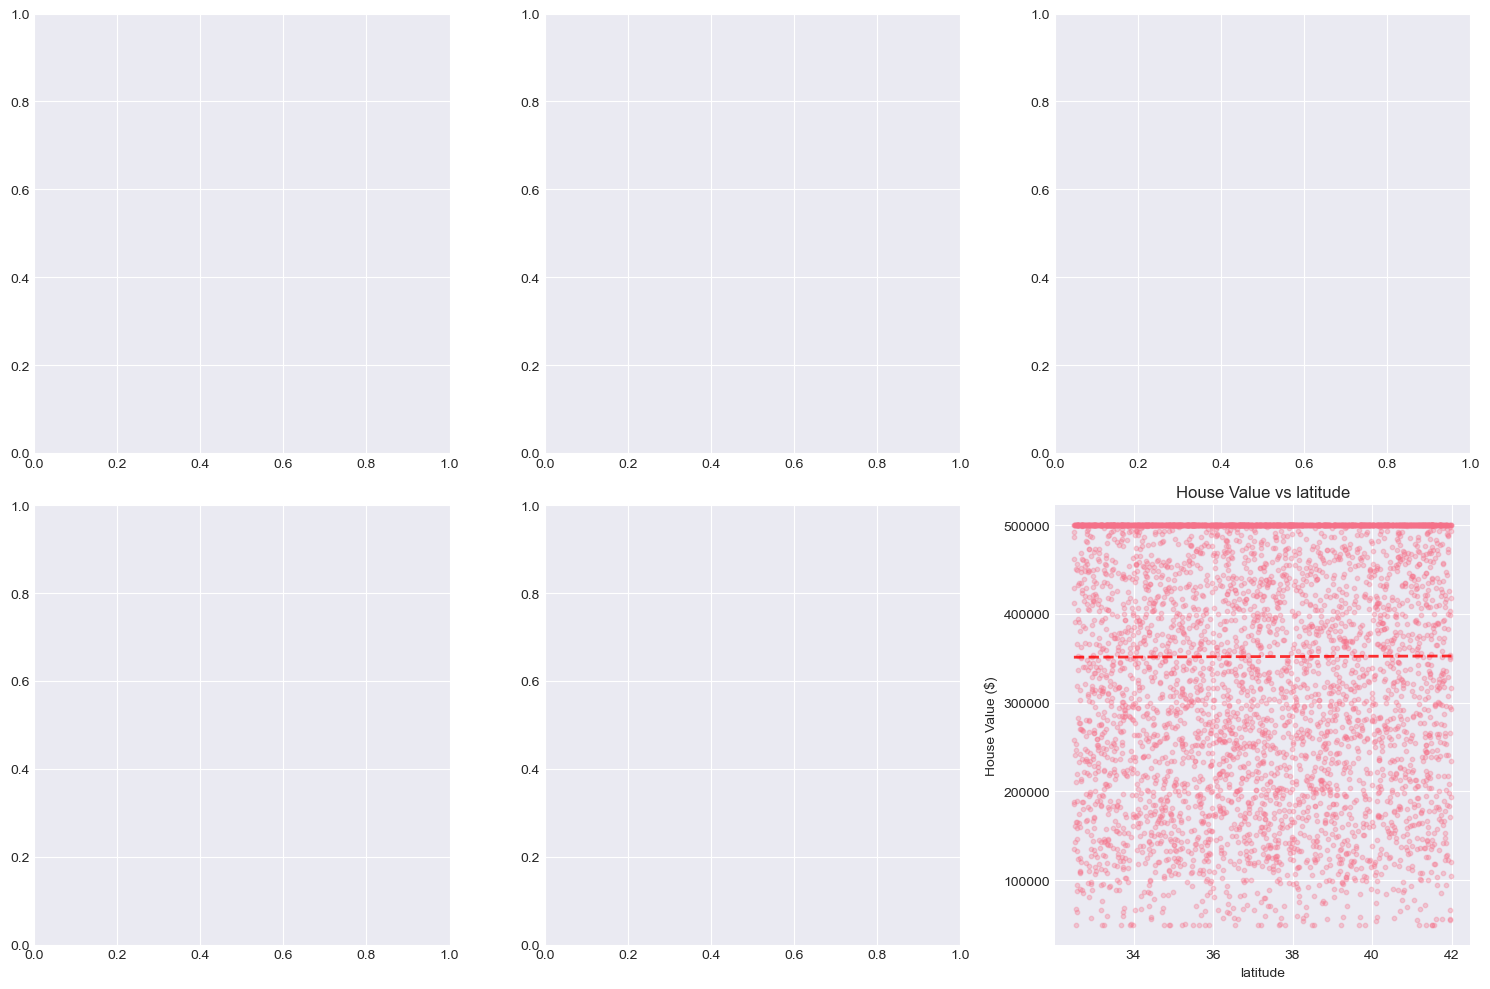

In [18]:
# Log transform 
axes[2].hist(np.log1p(df['median_house_value']), bins=50, 
edgecolor='black', alpha=0.7) 
axes[2].set_xlabel('Log(House Value)') 
axes[2].set_ylabel('Frequency') 
axes[2].set_title('Log-Transformed Distribution') 
plt.tight_layout() 
plt.show() 
# %% 
# Correlation with target variable 
numeric_cols = df.select_dtypes(include=[np.number]).columns 
correlations = df[numeric_cols].corr()['median_house_value'].sort_values(ascending=False) 
plt.figure(figsize=(10, 8)) 
correlations.drop('median_house_value').plot(kind='bar') 
plt.title('Feature Correlation with House Value') 
plt.xlabel('Features') 
plt.ylabel('Correlation Coefficient') 
plt.xticks(rotation=45) 
plt.tight_layout() 
plt.show() 
print("Top correlations with median_house_value:") 
print(correlations.head(10)) 
# %% 
# Scatter plots for important features 
fig, axes = plt.subplots(2, 3, figsize=(15, 10)) 
features = ['median_income', 'housing_median_age', 'total_rooms',  'population', 'households', 'latitude'] 
for idx, feature in enumerate(features): 
  row = idx // 3 
  col = idx % 3 
axes[row, col].scatter(df[feature], df['median_house_value'], 
alpha=0.3, s=10) 
axes[row, col].set_xlabel(feature) 
axes[row, col].set_ylabel('House Value ($)') 
axes[row, col].set_title(f'House Value vs {feature}') 
# Add trend line 
z = np.polyfit(df[feature], df['median_house_value'], 1) 
p = np.poly1d(z) 
axes[row, col].plot(df[feature].sort_values(), 
p(df[feature].sort_values()),"r--", alpha=0.8, linewidth=2) 
plt.tight_layout() 
plt.show()

In [8]:
 #Prepare data for univariate regression 
X_univariate = df[['median_income']] 
y = df['median_house_value'] 
# Split data 
X_train_uni, X_test_uni, y_train, y_test = train_test_split( 
X_univariate, y, test_size=0.2, random_state=42 
) 
print(f"Training set size: {X_train_uni.shape[0]}") 
print(f"Test set size: {X_test_uni.shape[0]}")

Training set size: 4000
Test set size: 1000


In [9]:
 
# %% 
# Train univariate linear regression model 
uni_model = LinearRegression() 
uni_model.fit(X_train_uni, y_train) 


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
# Get coefficients 
print("Univariate Linear Regression Model:") 
print(f"Equation: House Value = ${uni_model.intercept_:,.2f} + ${uni_model.coef_[0]:,.2f} * Median_Income") 
print(f"\nInterpretation: Each $1 increase in median income increases house value by ${uni_model.coef_[0]:,.2f}") 
# %% 
# Make predictions 
y_pred_uni_train = uni_model.predict(X_train_uni) 
y_pred_uni_test = uni_model.predict(X_test_uni) 

Univariate Linear Regression Model:
Equation: House Value = $107,080.64 + $31,363.62 * Median_Income

Interpretation: Each $1 increase in median income increases house value by $31,363.62


In [11]:
# Evaluate model 
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_uni_train)) 
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_uni_test)) 
train_r2 = r2_score(y_train, y_pred_uni_train) 
test_r2 = r2_score(y_test, y_pred_uni_test) 
print("Univariate Model Performance:") 
print(f"Training RMSE: ${train_rmse:,.2f}") 
print(f"Test RMSE: ${test_rmse:,.2f}") 
print(f"Training R² Score: {train_r2:.4f}") 
print(f"Test R² Score: {test_r2:.4f}") 

Univariate Model Performance:
Training RMSE: $43,818.19
Test RMSE: $43,087.46
Training R² Score: 0.9018
Test R² Score: 0.9022


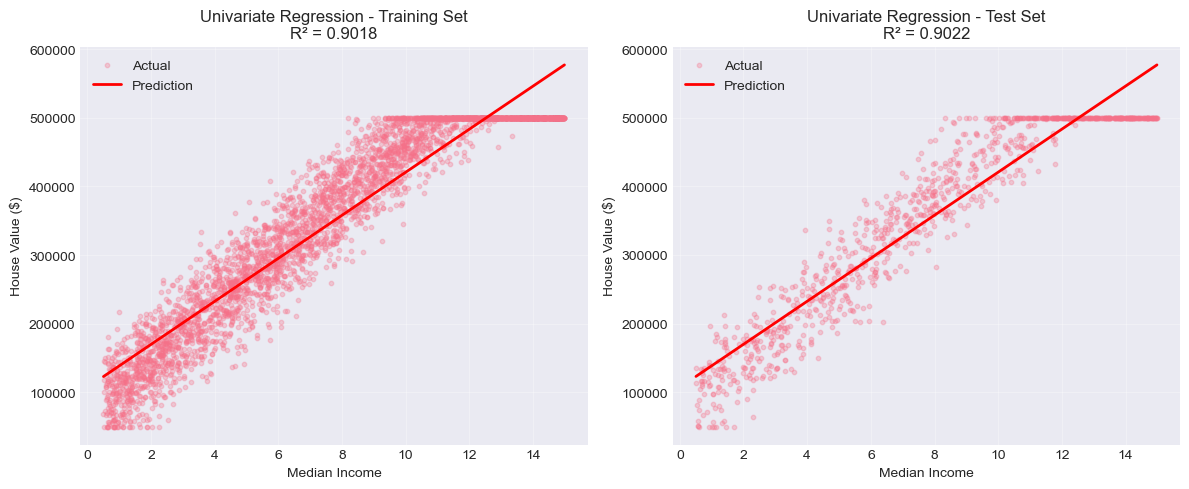

In [12]:
# %% 
# Visualize univariate regression results (SIMPLIFIED VERSION) 
plt.figure(figsize=(12, 5)) 
# Training data 
plt.subplot(1, 2, 1) 
plt.scatter(X_train_uni, y_train, alpha=0.3, s=10, label='Actual') 
# FIXED: Create a sorted version for the line 
X_train_sorted = X_train_uni.sort_values('median_income') 
y_pred_sorted = uni_model.predict(X_train_sorted) 
plt.plot(X_train_sorted, y_pred_sorted, color='red', linewidth=2, 
label='Prediction') 
plt.xlabel('Median Income') 
plt.ylabel('House Value ($)') 
plt.title(f'Univariate Regression - Training Set\nR² = {train_r2:.4f}') 
plt.legend() 
plt.grid(True, alpha=0.3) 

# Test data 
plt.subplot(1, 2, 2) 
plt.scatter(X_test_uni, y_test, alpha=0.3, s=10, label='Actual') 
# FIXED: Create a sorted version for the line 
X_test_sorted = X_test_uni.sort_values('median_income') 
y_pred_test_sorted = uni_model.predict(X_test_sorted) 
plt.plot(X_test_sorted, y_pred_test_sorted, color='red', linewidth=2, 
label='Prediction') 
plt.xlabel('Median Income') 
plt.ylabel('House Value ($)') 
plt.title(f'Univariate Regression - Test Set\nR² = {test_r2:.4f}') 
plt.legend() 
plt.grid(True, alpha=0.3)
plt.tight_layout() 
plt.show() 


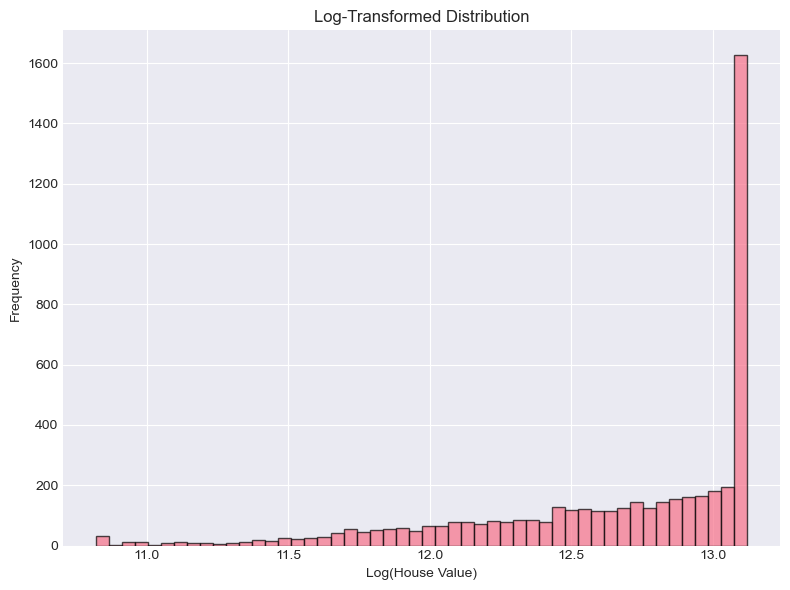

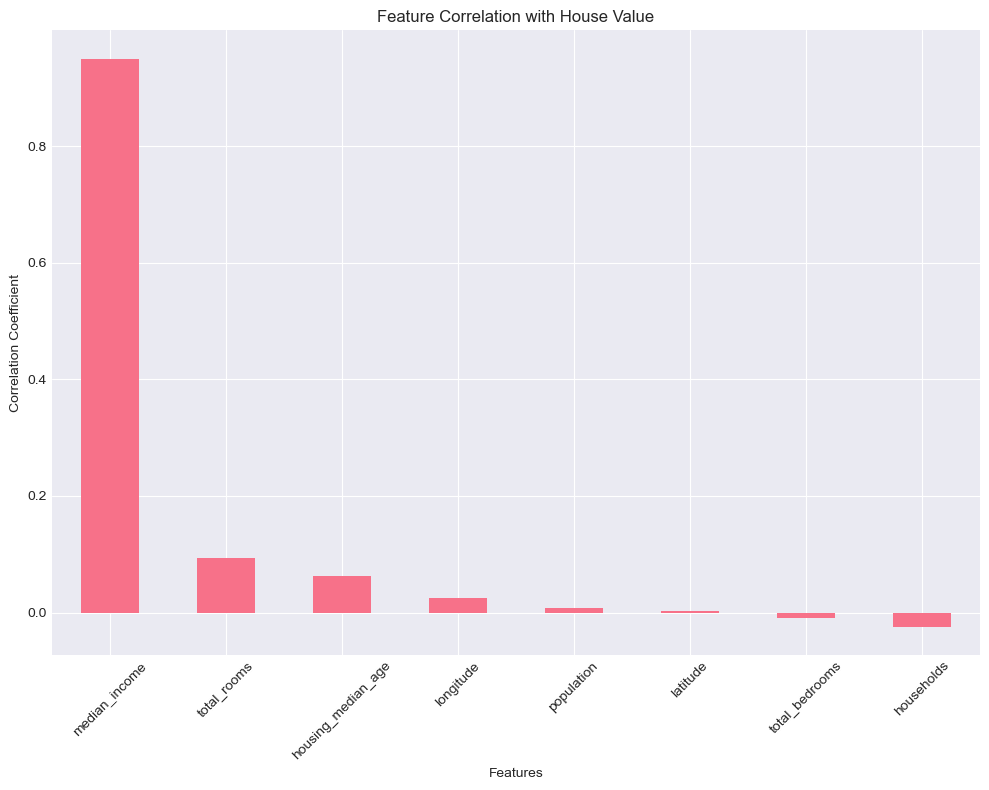

Top correlations with median_house_value:
median_house_value    1.000000
median_income         0.949690
total_rooms           0.093993
housing_median_age    0.062028
longitude             0.024634
population            0.008607
latitude              0.002769
total_bedrooms       -0.009236
households           -0.023969
Name: median_house_value, dtype: float64


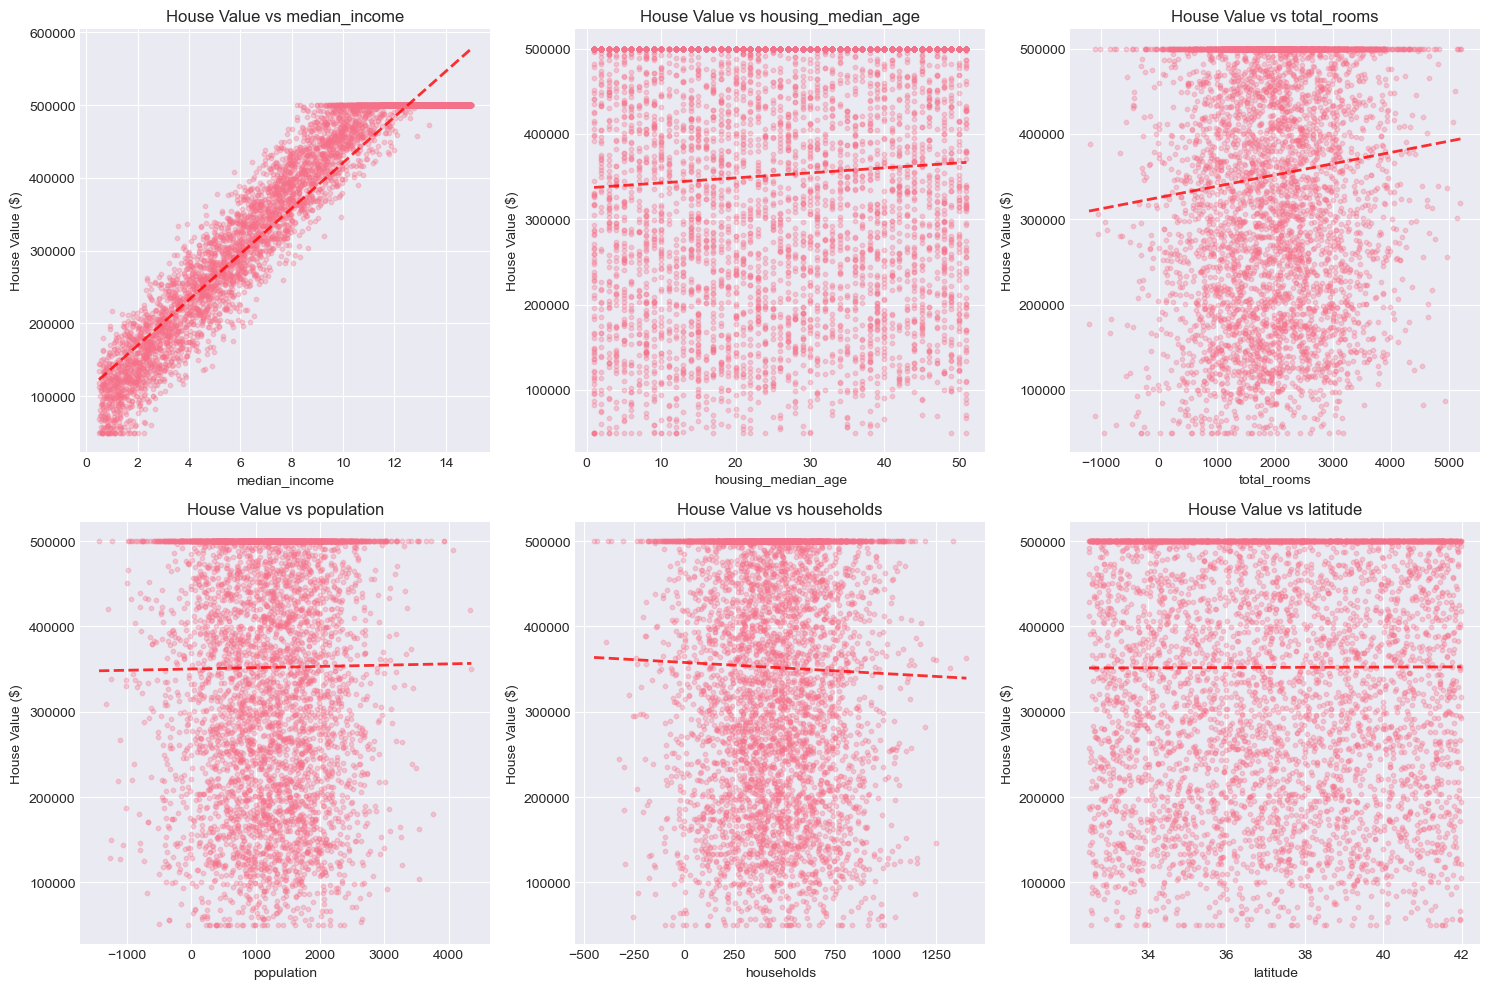

In [6]:
# Log transform 
import numpy as np
import matplotlib.pyplot as plt
# Create a separate figure for the histogram
plt.figure(figsize=(8, 6))
plt.hist(np.log1p(df['median_house_value']), bins=50, edgecolor='black', alpha=0.7) 
plt.xlabel('Log(House Value)') 
plt.ylabel('Frequency') 
plt.title('Log-Transformed Distribution') 
plt.tight_layout() 
plt.show() 

# %% 
# Correlation with target variable 
numeric_cols = df.select_dtypes(include=[np.number]).columns 
correlations = df[numeric_cols].corr()['median_house_value'].sort_values(ascending=False) 
plt.figure(figsize=(10, 8)) 
correlations.drop('median_house_value').plot(kind='bar') 
plt.title('Feature Correlation with House Value') 
plt.xlabel('Features') 
plt.ylabel('Correlation Coefficient') 
plt.xticks(rotation=45) 
plt.tight_layout() 
plt.show() 
print("Top correlations with median_house_value:") 
print(correlations.head(10)) 

# %% 
# Scatter plots for important features 
fig, axes = plt.subplots(2, 3, figsize=(15, 10)) 
features = ['median_income', 'housing_median_age', 'total_rooms',  
'population', 'households', 'latitude'] 
for idx, feature in enumerate(features): 
   row = idx // 3 
   col = idx % 3 
   axes[row, col].scatter(df[feature], df['median_house_value'], 
   alpha=0.3, s=10) 
   axes[row, col].set_xlabel(feature) 
   axes[row, col].set_ylabel('House Value ($)') 
   axes[row, col].set_title(f'House Value vs {feature}') 
   # Add trend line 
   z = np.polyfit(df[feature], df['median_house_value'], 1) 
   p = np.poly1d(z) 
   axes[row, col].plot(df[feature].sort_values(), 
   p(df[feature].sort_values()),"r--", alpha=0.8, linewidth=2) 
plt.tight_layout() 
plt.show()

In [13]:
df


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-120.754599,36.239537,32,2364,433,1213,91,2.791103,175259,NEAR BAY
1,-114.992857,36.997639,36,1872,59,1169,367,8.437746,467922,INLAND
2,-117.180061,40.618200,50,2373,538,476,916,9.032428,415249,INLAND
3,-118.513415,35.730042,37,3874,496,1757,194,10.763908,500001,<1H OCEAN
4,-122.939814,40.761672,48,762,530,1447,594,9.256520,400218,<1H OCEAN
...,...,...,...,...,...,...,...,...,...,...
4995,-115.526027,40.647732,45,1125,352,1134,484,0.611044,89291,NEAR OCEAN
4996,-123.306190,41.026334,8,2524,720,-551,7,11.514381,500001,INLAND
4997,-121.221572,41.493725,39,2402,108,1827,350,6.811629,376451,NEAR BAY
4998,-116.342546,36.276136,13,2547,650,1618,785,2.298872,175405,<1H OCEAN


In [15]:
df["ocean_proximity"].unique()

array(['NEAR BAY', 'INLAND', '<1H OCEAN', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)